In [1239]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [1240]:
df = pd.read_csv('../data/processed/board_games_clean.csv')

In [1241]:
df.head()

,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,belong_to_family
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,0,1,0
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,0,2,0
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,4.955827,6.727432,4.158883,...,0,0,0,0,0,0,0,0,3,0
3,11404,LetterFlip,2004,1.4216,2,2,7,4.955827,5.043425,2.079442,...,0,0,0,0,0,0,0,0,1,0
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,0,2,0


In [1242]:
df_pattern = df.copy()

###PREPROCESSING

In [1243]:
#Il pattern mining non può essere eseguito su variabili continue, quindi trasformiamo le variabili numeriche in categoriche,
# e droppo quelle che non servono, iniziando dalle colonne rank
df_pattern = df_pattern.drop(columns = [col for col in df.columns if col.startswith('Rank')])


In [1244]:
#Droppo anche colonne non utili
df_pattern = df_pattern.drop(columns = ['BGGId', 'Name'])

In [1245]:
#droppo numwish e numweightvotes perchè creerebbero pattern ovvi con numowned
df_pattern = df_pattern.drop(columns = ['NumWish', 'NumWeightVotes'])

In [1246]:
#Droppo mfgagerec e decido di analizzare solo l'età raccomandata dalla community (comagerec)
df_pattern = df_pattern.drop(columns = ['MfgAgeRec'])

In [1247]:
#trasformo la colonna Yearpublished in 3 categorie: classic (<=2000), modern (2001-2015), recent (>=2016)
def categorize_year(year):
    if year <= 2000:
        return 'classic(<2000)'
    elif 2001 <= year <= 2015:
        return 'modern(2001-2015)'
    else:
        return 'recent(>=2016)'
df_pattern['YearPublished'] = df_pattern['YearPublished'].apply(categorize_year)


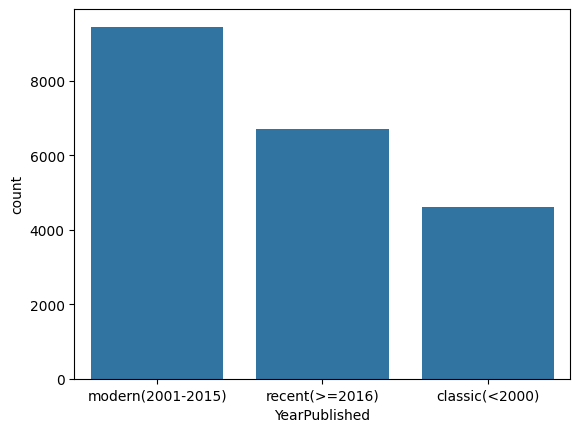

In [1248]:
#vedo la distribuzione di YearPublished
sns.countplot(data=df_pattern, x='YearPublished')
plt.show()

In [1249]:
#trasformo la colonna Comweight in 3 categorie: easy (<=2), medium (2-3), difficult (>=3)
def categorize_comweight(weight):
    if weight <= 2:
        return 'easy(<2)'
    elif 2 < weight <= 3:
        return 'medium_diff(2-3)'
    else:
        return 'difficult(>=3)'
df_pattern['ComWeight'] = df_pattern['ComWeight'].apply(categorize_comweight)

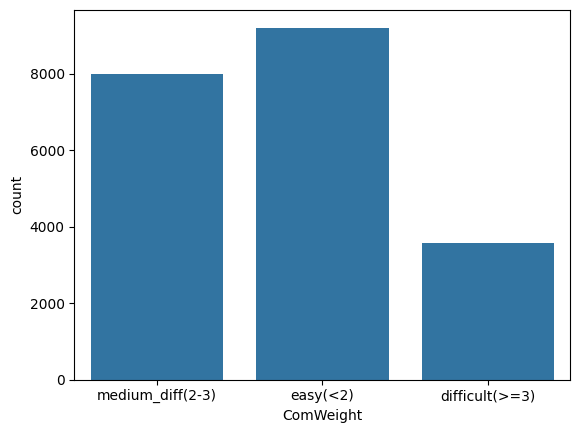

In [1250]:
#vedo la distribuzione di comweight
sns.countplot(data=df_pattern, x='ComWeight')
plt.show()

In [1251]:
NumOwned_4 = df_pattern[df_pattern['NumOwned'] >= 4]
NumOwned_5 = df_pattern[df_pattern['NumOwned'] >= 5]
NumOwned_5_5 = df_pattern[df_pattern['NumOwned'] >= 5.5]
NumOwned_6 = df_pattern[df_pattern['NumOwned'] >= 6]
NumOwned_7 = df_pattern[df_pattern['NumOwned'] >= 7]
NumOwned_8 = df_pattern[df_pattern['NumOwned'] >= 8]
NumOwned_9 = df_pattern[df_pattern['NumOwned'] >= 9]
NumOwned_10 = df_pattern[df_pattern['NumOwned'] >= 10]
print(len(NumOwned_4))
print(len(NumOwned_5))
print(len(NumOwned_5_5))
print(len(NumOwned_6))
print(len(NumOwned_7))
print(len(NumOwned_8))
print(len(NumOwned_9))
len(NumOwned_10)

20283
15909
12540
9302
4642
1998
700


211

In [1252]:
#Divido la colonna numowned in 4 categorie: low popularity(>5), medium (5-6.5), popular (6.5-8), best seller (8+)
def categorize_numowned(num):
    if num <= 5:
        return 'low popularity'
    elif 5 < num <= 6.5:
        return 'medium popularity'
    elif 6.5 < num <= 8:
        return 'popular'
    else:
        return 'best seller'
df_pattern['NumOwned'] = df_pattern['NumOwned'].apply(categorize_numowned)

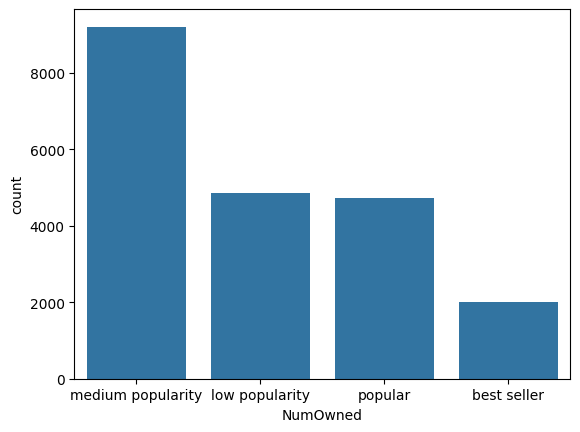

In [1253]:
#vedo la distribuzione dei giochi in numowned
sns.countplot(data=df_pattern, x='NumOwned')
plt.show()

In [1254]:
#Trasformo il rating in low, medium, high
def categorize_rating(rating):
    if rating == 1:
        return 'low rating'
    elif rating == 2:
        return 'medium rating'
    else:
        return 'high rating'
df_pattern['Rating'] = df_pattern['Rating'].apply(categorize_rating)

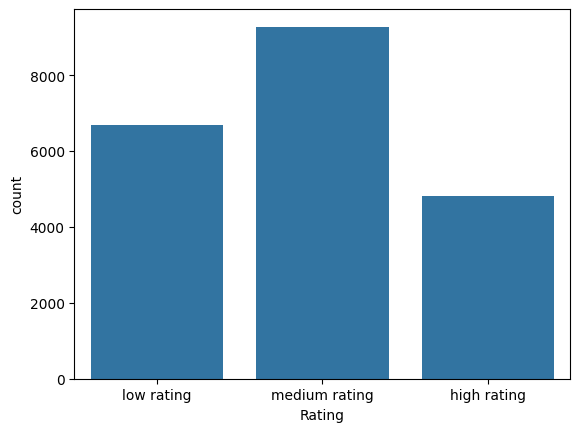

In [1255]:
#distribuzione del rating
sns.countplot(data=df_pattern, x='Rating')
plt.show()

In [1256]:
#faccio una media tra le colonne minplayers e maxplayers per ottenere una colonna unica numplayers
df_pattern['NumPlayers'] = (df_pattern['MinPlayers'] + df_pattern['MaxPlayers']) / 2
df_pattern = df_pattern.drop(columns = ['MinPlayers', 'MaxPlayers'])

In [1257]:
#Converto a interi la colonna NumPlayers
df_pattern['NumPlayers'] = df_pattern['NumPlayers'].astype(int)

In [1258]:
#Divido la colonna numplayers in 3 categorie: solo/couple games (<= 2), group games (2-4), party games (4+)
def categorize_numplayers(num):
    if num <= 2:
        return 'solo/couple games(<=2)'
    elif 2 < num <= 4:
        return 'group games(2-4)'
    else:
        return 'party games(4+)'
df_pattern['NumPlayers'] = df_pattern['NumPlayers'].apply(categorize_numplayers)

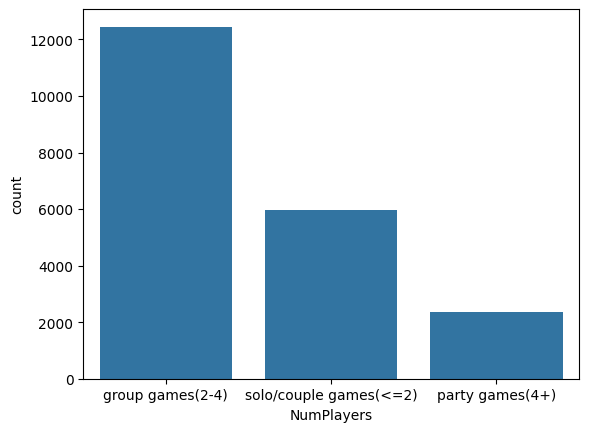

In [1259]:
sns.countplot(data=df_pattern, x='NumPlayers')
plt.show()

In [1260]:
#anche tra ComMaxPlaytime e ComMinPlaytime faccio la media e ottengo la colonna Playtime
df_pattern['Playtime'] = (df_pattern['ComMinPlaytime'] + df_pattern['ComMaxPlaytime']) / 2
df_pattern = df_pattern.drop(columns = ['ComMinPlaytime', 'ComMaxPlaytime'])

In [1261]:
#Applico qcut su Playtime per dividere in 4 categorie: short, medium, long, very long
df_pattern['Playtime'] = pd.qcut(df_pattern['Playtime'], q=4, labels=['short time', 'medium time', 'long time', 'very long time'])


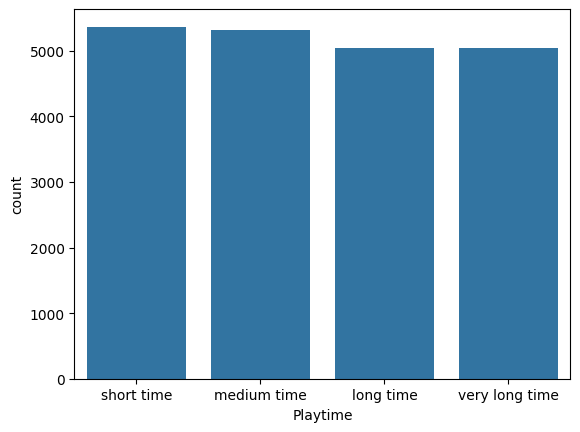

In [1262]:
#vedo la distribuzione del playtime
sns.countplot(data=df_pattern, x='Playtime')
plt.show()

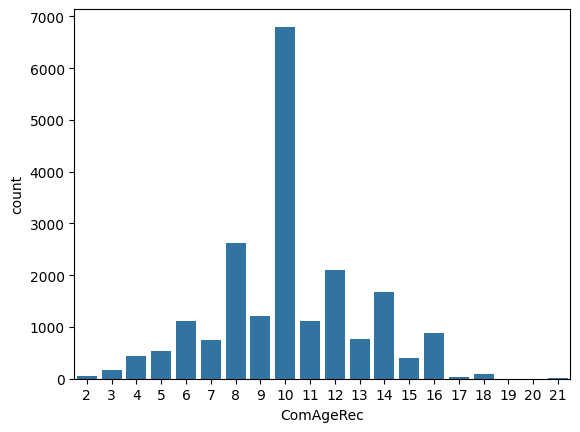

In [1263]:
#ved la distribuzione di comagerec
sns.countplot(data=df_pattern, x='ComAgeRec')
plt.show()


In [1264]:
#divido comagerec in 3 categorie: kids (<=9), pre-teens (9-13), teens/adults (13+)
def categorize_age(age):
    if age <= 9:
        return 'kids(<=9)'
    elif 9 < age <= 13:
        return 'pre-teens(9-13)'
    else:
        return 'teens/adults(13+)'
df_pattern['ComAgeRec'] = df_pattern['ComAgeRec'].apply(categorize_age)

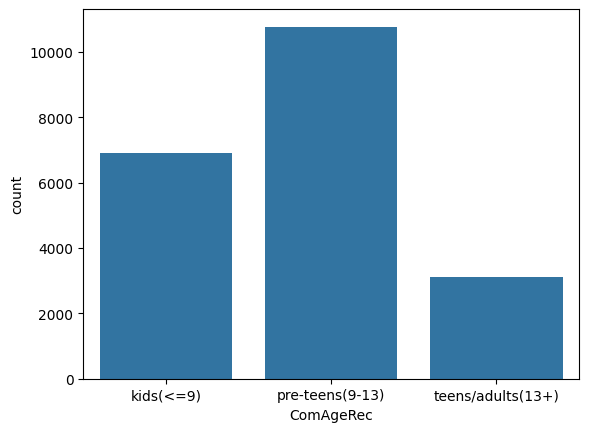

In [1265]:
sns.countplot(data=df_pattern, x='ComAgeRec')
plt.show()

In [1266]:
num_expansions0 = df_pattern[df_pattern['NumExpansions'] == 0]
num_expansionsnot0 = df_pattern[df_pattern['NumExpansions'] > 0]
print(len(num_expansions0))
print(len(num_expansionsnot0))

15291
5482


In [1267]:
num_implementations0 = df_pattern[df_pattern['NumImplementations'] == 0]
num_implementationsnot0 = df_pattern[df_pattern['NumImplementations'] > 0]
print(len(num_implementations0))
print(len(num_implementationsnot0))

16088
4685


In [1268]:
#Visto che numimplementations e numexpansions presentano molti valori uguali a 0, decido di trasformare le due colonne in
#binarie e chiamarle HasExpansions e HasImplementations
df_pattern['HasExpansions'] = np.where(df_pattern['NumExpansions'] > 0, 'HasExpansion', 'HasNotExpansion')
df_pattern['HasImplementations'] = np.where(df_pattern['NumImplementations'] > 0, 'HasImplementation', 'HasNotImplementation')
df_pattern = df_pattern.drop(columns = ['NumExpansions', 'NumImplementations'])

In [1269]:
#Languageease la divido in 3 categorie usando qcut
df_pattern['LanguageEase'] = pd.qcut(df_pattern['LanguageEase'], q=3, labels=['easy_language', 'medium_language', 'difficult_language'])

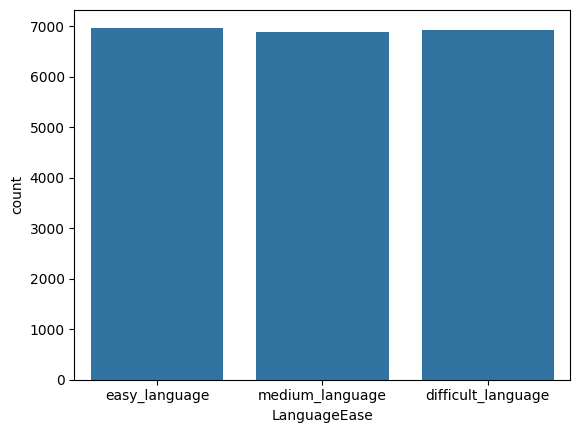

In [1270]:
#Vedo la distribuzione di LanguageEase
sns.countplot(data=df_pattern, x='LanguageEase')
plt.show()

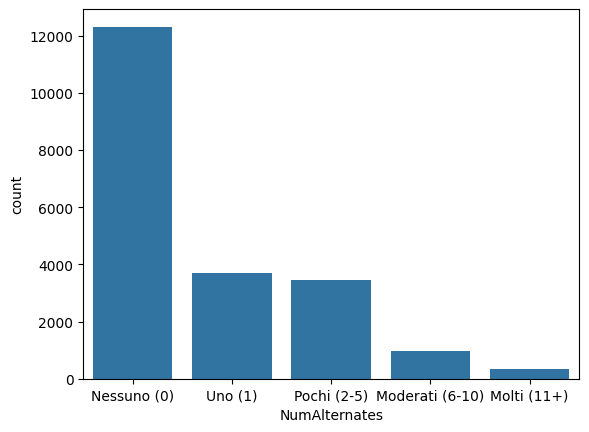

In [1271]:
#Controllo la distribuzione di NumAlternates
sns.countplot(data=df_pattern, x='NumAlternates')
plt.show()

In [1272]:
#Ritengo utile per il pattern mining trasformare la colonna NumAlternates in binaria
df_pattern['HasAlternates'] = np.where(df_pattern['NumAlternates'] != 'Nessuno (0)', 'HasAlternates', 'HasNotAlternates')
df_pattern = df_pattern.drop(columns = ['NumAlternates'])

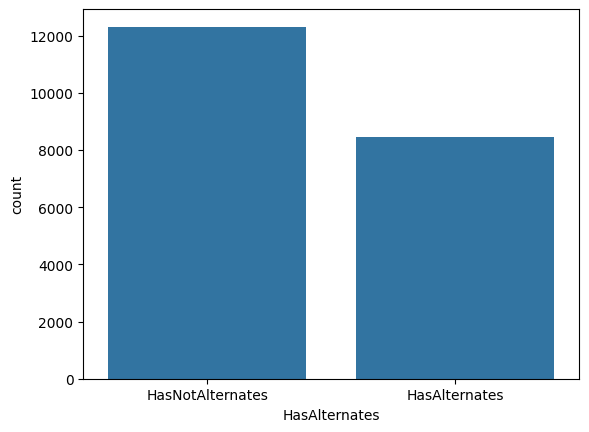

In [1273]:
sns.countplot(data=df_pattern, x='HasAlternates')
plt.show()

In [1274]:
# 2. Identifichiamo le colonne binarie (quelle che hanno ancora 0 e 1)
# Basandoci sul tuo file, queste sono le colonne da IsReimplementation a belong_to_family
binary_cols = [
    'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy', 
    'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party', 
    'Cat:Childrens', 'belong_to_family'
]

# Trasformiamo 0 e 1 in stringhe leggibili (es: 1 -> "Kickstarted", 0 -> "No_Kickstarted")
for col in binary_cols:
    df_pattern[col] = df_pattern[col].map({1: col, 0: "No_" + col})



In [1275]:
#salvo il nuovo dataset pulito per il pattern mining
df_pattern.to_csv('../data/processed/board_games_pattern_mining.csv', index=False)

In [1276]:
X = df_pattern.values.tolist()
X[0]

['modern(2001-2015)',
 'medium_diff(2-3)',
 'kids(<=9)',
 'difficult_language',
 'medium popularity',
 'No_IsReimplementation',
 'No_Kickstarted',
 'No_Cat:Thematic',
 'No_Cat:Strategy',
 'No_Cat:War',
 'No_Cat:Family',
 'No_Cat:CGS',
 'No_Cat:Abstract',
 'No_Cat:Party',
 'No_Cat:Childrens',
 'low rating',
 'No_belong_to_family',
 'group games(2-4)',
 'medium time',
 'HasExpansion',
 'HasNotImplementation',
 'HasNotAlternates']

###APRIORI

In [1277]:
from fim import apriori

###FINDING FREQUENT, CLOSED AND MAXIMAL ITEMSETS

In [1278]:
#Visto che le colonne delle categorie creano troppi frequent itemsets, provo a filtrarle
# Filtro i dati eliminando le etichette che indicano che un gioco non appartiene a una categoria

#Dopo aver cercato dei closed itemsets, vedo che quasi tutti i frequent itemsets trovati hanno al loro interno HasNotExpansion
# o HasNotImplementation o HasNotAlternates, quindi decido di rimuovere anche questi dal dataset

voci_da_escludere = ["No_", "HasNot"]

X_clean = [[item for item in row if not any(esc in str(item) for esc in voci_da_escludere)] for row in X]



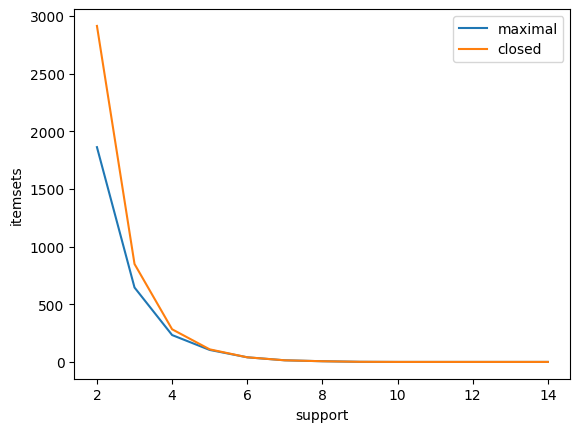

In [1279]:
#vedo il support plot per capire qual è il miglior supporto da usare
zmin = 4
len_max_it = []
len_cl_it = []
max_supp = 15
for i in range(2, max_supp):
    max_itemsets = apriori(X_clean, target="m", supp=i, zmin=zmin)
    cl_itemsets = apriori(X_clean, target="c", supp=i, zmin=zmin)
    len_max_it.append(len(max_itemsets))
    len_cl_it.append(len(cl_itemsets))

plt.plot(np.arange(2, max_supp), len_max_it, label="maximal")
plt.plot(np.arange(2, max_supp), len_cl_it, label="closed")
plt.legend()
plt.xlabel("support")
plt.ylabel("itemsets")

plt.show()

#A giudicare dal support plot il miglior supporto da usare sembra essere il 4%, da lì in poi closed e maximal quasi coincidono

In [1280]:
# Cerco i frequent itemsets con un supporto del 4%, avendo precedentemente provato con zmin uguale a 2 e 3, che tuttavia porta ad
#association rules troppo ovvie, provo ad alzare lo zmin a 4

zmin = 4
itemsets = apriori(X_clean, target="s", supp=4, zmin=zmin, report="s")
pd.DataFrame(itemsets, columns=["pattern>4%", "support"])

,pattern>4%,support
0,"(Cat:Family, kids(<=9), easy(<2), HasAlternates)",0.042026
1,"(Cat:Family, kids(<=9), easy(<2), group games(...",0.043903
2,"(Cat:Family, kids(<=9), HasAlternates, group g...",0.045107
3,"(teens/adults(13+), Cat:War, difficult(>=3), v...",0.052424
4,"(teens/adults(13+), Cat:War, difficult(>=3), s...",0.041929
...,...,...
278,"(HasAlternates, medium rating, modern(2001-201...",0.040293
279,"(HasAlternates, medium rating, modern(2001-201...",0.060415
280,"(HasAlternates, medium rating, pre-teens(9-13)...",0.051894
281,"(HasAlternates, modern(2001-2015), pre-teens(9...",0.058056


In [1281]:
# Ordina dal più frequente al meno frequente
df_frequent_itemsets_4 = pd.DataFrame(itemsets, columns=["pattern>4%", "support"])
df_frequent_itemsets_4.sort_values(by="support", ascending=False).head(20)

,pattern>4%,support
208,"(kids(<=9), easy(<2), HasAlternates, group gam...",0.096953
81,"(short time, kids(<=9), easy(<2), group games(...",0.089684
149,"(low rating, easy(<2), modern(2001-2015), grou...",0.085736
211,"(kids(<=9), easy(<2), modern(2001-2015), group...",0.085496
74,"(short time, kids(<=9), easy(<2), HasAlternates)",0.081693
129,"(low rating, kids(<=9), easy(<2), group games(...",0.081019
260,"(medium_diff(2-3), medium rating, pre-teens(9-...",0.078564
95,"(short time, easy(<2), HasAlternates, group ga...",0.076975
147,"(low rating, easy(<2), HasAlternates, group ga...",0.076301
141,"(low rating, medium popularity, easy(<2), grou...",0.075338


In [1282]:
# Cerco i closed itemsets con un supporto del 4%
itemsets = apriori(X_clean, target="c", supp=4, zmin=zmin, report="s")

pd.DataFrame(itemsets, columns=["pattern>4%", "support"])

,pattern>4%,support
0,"(Cat:Family, kids(<=9), easy(<2), HasAlternates)",0.042026
1,"(Cat:Family, kids(<=9), easy(<2), group games(...",0.043903
2,"(Cat:Family, kids(<=9), HasAlternates, group g...",0.045107
3,"(teens/adults(13+), Cat:War, difficult(>=3), v...",0.052424
4,"(teens/adults(13+), Cat:War, difficult(>=3), s...",0.041929
...,...,...
278,"(HasAlternates, medium rating, modern(2001-201...",0.040293
279,"(HasAlternates, medium rating, modern(2001-201...",0.060415
280,"(HasAlternates, medium rating, pre-teens(9-13)...",0.051894
281,"(HasAlternates, modern(2001-2015), pre-teens(9...",0.058056


In [1283]:
# Ordina dal più frequente al meno frequente
df_closed_itemsets_4 = pd.DataFrame(itemsets, columns=["pattern>4%", "support"])
df_closed_itemsets_4.sort_values(by="support", ascending=False).head(20)

,pattern>4%,support
208,"(kids(<=9), easy(<2), HasAlternates, group gam...",0.096953
81,"(short time, kids(<=9), easy(<2), group games(...",0.089684
149,"(low rating, easy(<2), modern(2001-2015), grou...",0.085736
211,"(kids(<=9), easy(<2), modern(2001-2015), group...",0.085496
74,"(short time, kids(<=9), easy(<2), HasAlternates)",0.081693
129,"(low rating, kids(<=9), easy(<2), group games(...",0.081019
260,"(medium_diff(2-3), medium rating, pre-teens(9-...",0.078564
95,"(short time, easy(<2), HasAlternates, group ga...",0.076975
147,"(low rating, easy(<2), HasAlternates, group ga...",0.076301
141,"(low rating, medium popularity, easy(<2), grou...",0.075338


In [1284]:
# Cerco i maximal itemsets con un supporto del 4%
itemsets = apriori(X_clean, target="m", supp=4, zmin=zmin, report="s")

pd.DataFrame(itemsets, columns=["pattern>4%", "support"])

,pattern>4%,support
0,"(Cat:Family, kids(<=9), easy(<2), HasAlternates)",0.042026
1,"(Cat:Family, kids(<=9), easy(<2), group games(...",0.043903
2,"(Cat:Family, kids(<=9), HasAlternates, group g...",0.045107
3,"(teens/adults(13+), Cat:War, difficult(>=3), v...",0.052424
4,"(teens/adults(13+), Cat:War, difficult(>=3), s...",0.041929
...,...,...
228,"(HasAlternates, medium rating, modern(2001-201...",0.040293
229,"(HasAlternates, medium rating, modern(2001-201...",0.060415
230,"(HasAlternates, medium rating, pre-teens(9-13)...",0.051894
231,"(HasAlternates, modern(2001-2015), pre-teens(9...",0.058056


In [1285]:
df_maximal_itemsets_4 = pd.DataFrame(itemsets, columns=["pattern>4%", "support"])
df_maximal_itemsets_4.sort_values(by="support", ascending=False).head(20)

,pattern>4%,support
213,"(medium_diff(2-3), medium rating, pre-teens(9-...",0.078564
214,"(medium_diff(2-3), modern(2001-2015), pre-teen...",0.069850
232,"(medium rating, modern(2001-2015), pre-teens(9...",0.068936
39,"(long time, medium_diff(2-3), pre-teens(9-13),...",0.066962
146,"(kids(<=9), difficult_language, easy(<2), grou...",0.063833
212,"(medium_diff(2-3), medium rating, modern(2001-...",0.061859
155,"(kids(<=9), easy_language, easy(<2), group gam...",0.061137
206,"(medium_diff(2-3), medium popularity, pre-teen...",0.060415
229,"(HasAlternates, medium rating, modern(2001-201...",0.060415
74,"(short time, medium popularity, easy(<2), grou...",0.059019


###RULES

In [1286]:
conf = 70
supp = 6
rules = apriori(X_clean, target="r", supp=supp, zmin=zmin, conf=conf, report="aScl")
rules_df = pd.DataFrame(
    rules,
    columns=[
        "consequent",
        "antecedent",
        "abs_support",
        "%_support",
        "confidence",
        "lift",
    ],
)
rules_df.sort_values(by="lift", axis=0, ascending=False)

,consequent,antecedent,abs_support,%_support,confidence,lift
8,Cat:War,"(teens/adults(13+), very long time, solo/coupl...",1385,6.667309,0.938983,5.983281
15,Cat:War,"(teens/adults(13+), solo/couple games(<=2), me...",1184,5.699706,0.936709,5.968789
25,Cat:War,"(very long time, solo/couple games(<=2), mediu...",1261,6.070380,0.876303,5.583878
11,Cat:War,"(teens/adults(13+), very long time, medium pop...",1200,5.776729,0.873999,5.569194
5,teens/adults(13+),"(Cat:War, very long time, solo/couple games(<=...",984,4.736918,0.780333,5.222248
...,...,...,...,...,...,...
85,group games(2-4),"(low rating, modern(2001-2015), pre-teens(9-13))",1194,5.747846,0.703595,1.173957
27,group games(2-4),"(low popularity, low rating, easy(<2))",1121,5.396428,0.702381,1.171932
122,group games(2-4),"(kids(<=9), HasAlternates, medium rating)",1236,5.950031,0.701078,1.169758
110,group games(2-4),"(kids(<=9), medium popularity, medium rating)",878,4.226640,0.700718,1.169158


In [1287]:
#Avendo trovato molte associazioni, elimino da rules_df le regole che hanno lift minore di 1.50, e mi concentro su quelle con lift più alto,
#ciò significa considerare solo i casi in cui la presenza dell'antecedent aumenta di oltre il 50% la probabilità della presenza del consequent,
#e quindi le regole più significative
rules_df = rules_df[rules_df['lift'] >= 1.50]
rules_df.sort_values(by="lift", axis=0, ascending=False)

,consequent,antecedent,abs_support,%_support,confidence,lift
8,Cat:War,"(teens/adults(13+), very long time, solo/coupl...",1385,6.667309,0.938983,5.983281
15,Cat:War,"(teens/adults(13+), solo/couple games(<=2), me...",1184,5.699706,0.936709,5.968789
25,Cat:War,"(very long time, solo/couple games(<=2), mediu...",1261,6.070380,0.876303,5.583878
11,Cat:War,"(teens/adults(13+), very long time, medium pop...",1200,5.776729,0.873999,5.569194
5,teens/adults(13+),"(Cat:War, very long time, solo/couple games(<=...",984,4.736918,0.780333,5.222248
...,...,...,...,...,...,...
77,easy(<2),"(low rating, easy_language, group games(2-4))",1059,5.097964,0.707415,1.595909
102,easy(<2),"(kids(<=9), easy_language, group games(2-4))",1270,6.113705,0.705948,1.592599
65,easy(<2),"(low rating, medium_language, pre-teens(9-13))",1230,5.921148,0.705680,1.591995
92,easy(<2),"(kids(<=9), difficult_language, group games(2-4))",1326,6.383286,0.705319,1.591181


In [1288]:
rules_df.sort_values(by="lift", axis=0, ascending=False)

,consequent,antecedent,abs_support,%_support,confidence,lift
8,Cat:War,"(teens/adults(13+), very long time, solo/coupl...",1385,6.667309,0.938983,5.983281
15,Cat:War,"(teens/adults(13+), solo/couple games(<=2), me...",1184,5.699706,0.936709,5.968789
25,Cat:War,"(very long time, solo/couple games(<=2), mediu...",1261,6.070380,0.876303,5.583878
11,Cat:War,"(teens/adults(13+), very long time, medium pop...",1200,5.776729,0.873999,5.569194
5,teens/adults(13+),"(Cat:War, very long time, solo/couple games(<=...",984,4.736918,0.780333,5.222248
...,...,...,...,...,...,...
77,easy(<2),"(low rating, easy_language, group games(2-4))",1059,5.097964,0.707415,1.595909
102,easy(<2),"(kids(<=9), easy_language, group games(2-4))",1270,6.113705,0.705948,1.592599
65,easy(<2),"(low rating, medium_language, pre-teens(9-13))",1230,5.921148,0.705680,1.591995
92,easy(<2),"(kids(<=9), difficult_language, group games(2-4))",1326,6.383286,0.705319,1.591181


###RULES INTERESSANTI TROVATE (ho preso le rules più importanti per ogni colonna come consequent)

- teens/adults(13+), very_long_time, solo/couple_games --> Cat:War con abs_support di 1385 lift 5.983, con %support 6.667 e confidence 0.939
- very_long_time, solo/couple_games, medium_popularity --> teens/adults(13+) con abs_support di 1019, con %support di 4.905, con lift di 4.739 e confidence di 0.708
- teens/adults(13+), Cat:War, medium_popolarity --> very_long_time con abs_support di 1200, con lift di 3.442, con %support di 5.777, con confidence di 0.834
- teens/adults(13+), Cat:War, medium_popolarity --> solo_couple_games con abs_support di 1184, con %support di 5.7, con lift di 2.872, con confidence 0.79
- classic(<2000), difficult_easy, group_games (2-4 players) --> low_rating con abs_support di 1020, con %support di 4.91, con lift di 2.45, con confidence di 0.789
- short_time, easy, HasAlternates, group_games --> kids(<=9) con abs_support di 1189, con %support di 5.723, con lift di 2.24, con confidence di 0.74

###FP-GROWTH

In [1289]:
from fim import fpgrowth

In [1290]:
help(fpgrowth)

Help on built-in function fpgrowth in module fim:

fpgrowth(...)
    fpgrowth (tracts, target='s', supp=10, zmin=1, zmax=None, report='a',
              eval='x', agg='x', thresh=10, prune=Nobe, algo='s', mode='',
              border=None)
    Find frequent item sets with the FP-growth algorithm.
    tracts  transaction database to mine (mandatory)
            The database must be an iterable of transactions;
            each transaction must be an iterable of items;
            each item must be a hashable object.
            If the database is a dictionary, the transactions are
            the keys, the values their (integer) multiplicities.
    target  type of frequent item sets to find     (default: s)
            s/a   sets/all   all     frequent item sets
            c     closed     closed  frequent item sets
            m     maximal    maximal frequent item sets
            g     gens       generators
            r     rules      association rules
    supp    minimum support 

In [1291]:
#uso lo stesso supporto e zmin usati con apriori
itemsets = fpgrowth(X_clean, target="s", supp=4, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["pattern>=4%", "support"])

,pattern>=4%,support
0,"(medium rating, modern(2001-2015), pre-teens(9...",6.893564
1,"(HasAlternates, modern(2001-2015), pre-teens(9...",5.805613
2,"(HasAlternates, medium rating, pre-teens(9-13)...",5.189429
3,"(HasAlternates, medium rating, modern(2001-201...",6.041496
4,"(HasAlternates, medium rating, modern(2001-201...",4.029269
...,...,...
278,"(teens/adults(13+), Cat:War, difficult(>=3), s...",4.192943
279,"(teens/adults(13+), Cat:War, difficult(>=3), v...",5.242382
280,"(Cat:Family, kids(<=9), HasAlternates, group g...",4.510663
281,"(Cat:Family, kids(<=9), easy(<2), group games(...",4.390314


In [1292]:
# Ordina dal più frequente al meno frequente
df_frequent_itemsets_fp4 = pd.DataFrame(itemsets, columns=["pattern>4%", "support"])
df_frequent_itemsets_fp4.sort_values(by="support", ascending=False).head(20)

,pattern>4%,support
74,"(kids(<=9), easy(<2), HasAlternates, group gam...",9.695278
201,"(short time, kids(<=9), easy(<2), group games(...",8.968372
133,"(low rating, easy(<2), modern(2001-2015), grou...",8.573629
71,"(kids(<=9), easy(<2), modern(2001-2015), group...",8.549560
208,"(short time, kids(<=9), easy(<2), HasAlternates)",8.169258
153,"(low rating, kids(<=9), easy(<2), group games(...",8.101863
22,"(medium_diff(2-3), medium rating, pre-teens(9-...",7.856352
187,"(short time, easy(<2), HasAlternates, group ga...",7.697492
135,"(low rating, easy(<2), HasAlternates, group ga...",7.630097
141,"(low rating, medium popularity, easy(<2), grou...",7.533818


In [1293]:
itemsets = fpgrowth(X_clean, target="c", supp=4, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["pattern>=4%", "support"])

,pattern>=4%,support
0,"(Cat:Family, kids(<=9), easy(<2), HasAlternates)",4.202571
1,"(Cat:Family, kids(<=9), easy(<2), group games(...",4.390314
2,"(Cat:Family, kids(<=9), HasAlternates, group g...",4.510663
3,"(teens/adults(13+), Cat:War, difficult(>=3), v...",5.242382
4,"(teens/adults(13+), Cat:War, difficult(>=3), s...",4.192943
...,...,...
278,"(HasAlternates, medium rating, modern(2001-201...",4.029269
279,"(HasAlternates, medium rating, modern(2001-201...",6.041496
280,"(HasAlternates, medium rating, pre-teens(9-13)...",5.189429
281,"(HasAlternates, modern(2001-2015), pre-teens(9...",5.805613


In [1294]:
df_closed_itemsets_fp4 = pd.DataFrame(itemsets, columns=["pattern>4%", "support"])
df_closed_itemsets_fp4.sort_values(by="support", ascending=False).head(20)

,pattern>4%,support
208,"(kids(<=9), easy(<2), HasAlternates, group gam...",9.695278
81,"(short time, kids(<=9), easy(<2), group games(...",8.968372
149,"(low rating, easy(<2), modern(2001-2015), grou...",8.573629
211,"(kids(<=9), easy(<2), modern(2001-2015), group...",8.549560
76,"(short time, kids(<=9), easy(<2), HasAlternates)",8.169258
129,"(low rating, kids(<=9), easy(<2), group games(...",8.101863
260,"(medium_diff(2-3), medium rating, pre-teens(9-...",7.856352
95,"(short time, easy(<2), HasAlternates, group ga...",7.697492
147,"(low rating, easy(<2), HasAlternates, group ga...",7.630097
141,"(low rating, medium popularity, easy(<2), grou...",7.533818


In [1295]:
itemsets = fpgrowth(X_clean, target="m", supp=4, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["pattern>=4%", "support"])

,pattern>=4%,support
0,"(Cat:Family, kids(<=9), easy(<2), HasAlternates)",4.202571
1,"(Cat:Family, kids(<=9), easy(<2), group games(...",4.390314
2,"(Cat:Family, kids(<=9), HasAlternates, group g...",4.510663
3,"(teens/adults(13+), Cat:War, difficult(>=3), v...",5.242382
4,"(teens/adults(13+), Cat:War, difficult(>=3), s...",4.192943
...,...,...
228,"(HasAlternates, medium rating, modern(2001-201...",4.029269
229,"(HasAlternates, medium rating, modern(2001-201...",6.041496
230,"(HasAlternates, medium rating, pre-teens(9-13)...",5.189429
231,"(HasAlternates, modern(2001-2015), pre-teens(9...",5.805613


In [1296]:
df_maximal_itemsets_fp4 = pd.DataFrame(itemsets, columns=["pattern>4%", "support"])
df_maximal_itemsets_fp4.sort_values(by="support", ascending=False).head(20)

,pattern>4%,support
213,"(medium_diff(2-3), medium rating, pre-teens(9-...",7.856352
214,"(medium_diff(2-3), modern(2001-2015), pre-teen...",6.985029
232,"(medium rating, modern(2001-2015), pre-teens(9...",6.893564
39,"(long time, medium_diff(2-3), pre-teens(9-13),...",6.696192
146,"(kids(<=9), difficult_language, easy(<2), grou...",6.383286
212,"(medium_diff(2-3), medium rating, modern(2001-...",6.185914
155,"(kids(<=9), easy_language, easy(<2), group gam...",6.113705
206,"(medium_diff(2-3), medium popularity, pre-teen...",6.041496
229,"(HasAlternates, medium rating, modern(2001-201...",6.041496
74,"(short time, medium popularity, easy(<2), grou...",5.901892


In [1298]:
conf = 70
rules = fpgrowth(X_clean, target="r", supp=supp, zmin=zmin, conf=conf, report="aScl")
pd.DataFrame(
    rules,
    columns=[
        "consequent",
        "antecedent",
        "abs_support",
        "%_support",
        "confidence",
        "lift",
    ],
)

,consequent,antecedent,abs_support,%_support,confidence,lift
0,group games(2-4),"(kids(<=9), HasAlternates, modern(2001-2015))",1306,6.287007,0.725153,1.209927
1,group games(2-4),"(kids(<=9), HasAlternates, medium rating)",1236,5.950031,0.701078,1.169758
2,group games(2-4),"(kids(<=9), easy(<2), modern(2001-2015))",1776,8.549560,0.707288,1.180120
3,easy(<2),"(kids(<=9), modern(2001-2015), group games(2-4))",1776,8.549560,0.731165,1.649489
4,group games(2-4),"(kids(<=9), easy(<2), HasAlternates)",2014,9.695278,0.719543,1.200567
...,...,...,...,...,...,...
119,teens/adults(13+),"(Cat:War, very long time, solo/couple games(<=2))",1385,6.667309,0.746228,4.994009
120,teens/adults(13+),"(Cat:War, classic(<2000), very long time)",976,4.698407,0.746748,4.997488
121,Cat:War,"(teens/adults(13+), difficult(>=3), very long ...",1089,5.242382,0.781205,4.977906
122,teens/adults(13+),"(Cat:War, difficult(>=3), very long time)",1089,5.242382,0.756250,5.061076


In [1299]:
rules_df = rules_df[rules_df['lift'] >= 1.50]
rules_df.sort_values(by="lift", axis=0, ascending=False)

,consequent,antecedent,abs_support,%_support,confidence,lift
8,Cat:War,"(teens/adults(13+), very long time, solo/coupl...",1385,6.667309,0.938983,5.983281
15,Cat:War,"(teens/adults(13+), solo/couple games(<=2), me...",1184,5.699706,0.936709,5.968789
25,Cat:War,"(very long time, solo/couple games(<=2), mediu...",1261,6.070380,0.876303,5.583878
11,Cat:War,"(teens/adults(13+), very long time, medium pop...",1200,5.776729,0.873999,5.569194
5,teens/adults(13+),"(Cat:War, very long time, solo/couple games(<=...",984,4.736918,0.780333,5.222248
...,...,...,...,...,...,...
77,easy(<2),"(low rating, easy_language, group games(2-4))",1059,5.097964,0.707415,1.595909
102,easy(<2),"(kids(<=9), easy_language, group games(2-4))",1270,6.113705,0.705948,1.592599
65,easy(<2),"(low rating, medium_language, pre-teens(9-13))",1230,5.921148,0.705680,1.591995
92,easy(<2),"(kids(<=9), difficult_language, group games(2-4))",1326,6.383286,0.705319,1.591181


###COME PREVISTO, I DUE ALGORITMI DANNO GLI STESSI RISULTATI, ESSENDO EQUIVALENTI, NON HA SENSO CONTINUARE L'ANALISI SULL'FP GROWTH